In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X shape: torch.Size([1000, 2])
y shape: torch.Size([1000])
Classes: tensor([0, 1, 2, 3])


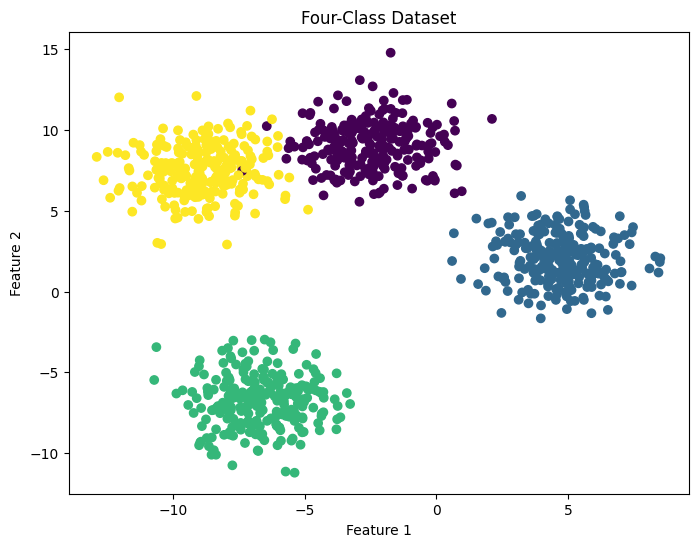

In [2]:
X, y = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    cluster_std=1.5,
    random_state=42
)
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.long)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", torch.unique(y))
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis")
plt.title("Four-Class Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
torch.manual_seed(42)
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
class BlobModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(2, 16)
        self.layer_2 = nn.Linear(16, 16)
        self.layer_3 = nn.Linear(16, 4)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.layer_1(x))
        x = self.relu(self.layer_2(x))
        x = self.layer_3(x)
        return x
model = BlobModel()
print(model)

BlobModel(
  (layer_1): Linear(in_features=2, out_features=16, bias=True)
  (layer_2): Linear(in_features=16, out_features=16, bias=True)
  (layer_3): Linear(in_features=16, out_features=4, bias=True)
  (relu): ReLU()
)


In [4]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.1
)

In [5]:
epochs = 100
for epoch in range(epochs):
    model.train()
    y_logits = model(X_train)
    loss = loss_fn(y_logits, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test)
        test_loss = loss_fn(test_logits, y_test)
        test_preds = torch.argmax(test_logits, dim=1)
        accuracy = (
            (test_preds == y_test).float().mean() * 100
        )
    if epoch % 10 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f} | "
            f"Test accuracy: {accuracy.item():.2f}%"
        )
print("training complete")

Epoch: 0 | Train loss: 1.5338 | Test loss: 1.1994 | Test accuracy: 11.50%
Epoch: 10 | Train loss: 0.3551 | Test loss: 0.3136 | Test accuracy: 98.50%
Epoch: 20 | Train loss: 0.1302 | Test loss: 0.1244 | Test accuracy: 99.50%
Epoch: 30 | Train loss: 0.0739 | Test loss: 0.0759 | Test accuracy: 99.00%
Epoch: 40 | Train loss: 0.0546 | Test loss: 0.0579 | Test accuracy: 99.00%
Epoch: 50 | Train loss: 0.0453 | Test loss: 0.0488 | Test accuracy: 99.00%
Epoch: 60 | Train loss: 0.0400 | Test loss: 0.0433 | Test accuracy: 99.00%
Epoch: 70 | Train loss: 0.0365 | Test loss: 0.0396 | Test accuracy: 99.00%
Epoch: 80 | Train loss: 0.0342 | Test loss: 0.0370 | Test accuracy: 99.00%
Epoch: 90 | Train loss: 0.0324 | Test loss: 0.0351 | Test accuracy: 99.00%
training complete


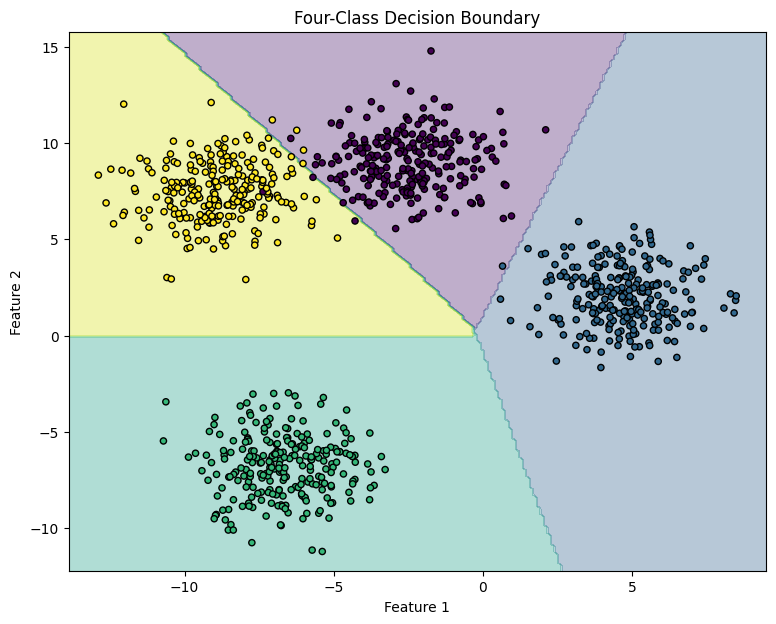

In [6]:
import numpy as np
def plot_multiclass_decision_boundary(model, X, y):
    X_np = X.detach().cpu().numpy()
    y_np = y.detach().cpu().numpy()
    x_min = X_np[:, 0].min() - 1
    x_max = X_np[:, 0].max() + 1
    y_min = X_np[:, 1].min() - 1
    y_max = X_np[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    grid_tensor = torch.tensor(grid, dtype=torch.float32)
    model.eval()
    with torch.inference_mode():
        logits = model(grid_tensor)
        predictions = torch.argmax(logits, dim=1)

    predictions = predictions.reshape(xx.shape).numpy()
    plt.figure(figsize=(9, 7))
    plt.contourf(
        xx, yy, predictions,
        alpha=0.35,
        cmap="viridis"
    )
    plt.scatter(
        X_np[:, 0],
        X_np[:, 1],
        c=y_np,
        cmap="viridis",
        edgecolors="black",
        s=20
    )
    plt.title("Four-Class Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()
plot_multiclass_decision_boundary(model, X, y)


In [7]:
new_sample = torch.tensor([[0.0, 0.0]], dtype=torch.float32)
model.eval()
with torch.inference_mode():
    logits = model(new_sample)
    probabilities = torch.softmax(logits, dim=1)
    predicted_class = torch.argmax(logits, dim=1)
print("New sample:", new_sample)
print("Logits:", logits)
print("Probabilities:", probabilities)
print("Predicted class:", predicted_class.item())


New sample: tensor([[0., 0.]])
Logits: tensor([[-0.4641,  0.4489, -0.1349, -0.3939]])
Probabilities: tensor([[0.1679, 0.4185, 0.2334, 0.1802]])
Predicted class: 1
